# CompuOpti : quels projets retenir et qui fait quoi ?

On cherche à choisir les projets à terminer, puis à répartir le travail entre les personnes. On compare d'abord le gain brut et les pénalités, puis le gain net et le nombre maximal de projets par personne.

Ce notebook lance les calculs sur les trois jeux fournis et sur les instances générées. On regarde ensuite les compromis obtenus et un exemple de planning. Les variables et contraintes Gurobi sont dans [src/modele.py](src/modele.py).


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
racine = Path.cwd()
if not (racine / "Datasets").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))
from src.donnees import lire_instance, dimensions
from src.generation import generer_instance
from src.resolution import calculer_front
from src.modele import construire_modele
from src.verification import evaluer_planning
identifiant = datetime.now(timezone.utc).strftime("gurobi_%Y%m%dT%H%M%S_%fZ")
sortie = racine / "resultats" / identifiant
sortie.mkdir(parents=True)
instances = {}
for nom in ["toy", "medium", "large"]:
    instances[nom] = lire_instance(racine / "Datasets" / (nom + "_instance.json"))
tableau_donnees = [{"instance": nom, **dimensions(d)} for nom, d in instances.items()]
display(pd.DataFrame(tableau_donnees))

,instance,jours,personnes,projets,competences,capacite,charge
0,toy,5,3,5,3,13,14
1,medium,22,5,15,10,102,135
2,large,36,6,25,10,193,272


## Modèle et hypothèses

Dans notre cas, une alternative du cours est un planning qui respecte les contraintes. $X_{ijkt}=1$ signifie que la personne $i$ travaille sur le projet $j$, pour la compétence $k$, au jour $t$. $Y_j$ indique la livraison dans l'horizon. $E_j$ est la date de fin et $L_j$ le retard.

Les variables $X$ n'existent que si la compétence est détenue et demandée, et si la personne est disponible. On impose une affectation au plus par personne et jour. Pour chaque projet et compétence :

$$\sum_{i,t}X_{ijkt}=n_{jk}Y_j.$$

On choisit de couvrir exactement le besoin des projets retenus : le travail partiel et les journées en trop ne rapportent rien ici. Cela renforce la condition $\sum X\ge nY$ donnée par le professeur. Plusieurs personnes peuvent travailler en parallèle et un projet peut être interrompu.

Le témoin binaire $U_{jt}$ repère le dernier jour travaillé : $\sum_t U_{jt}=Y_j$, le jour témoin contient du travail et aucune affectation ne peut le suivre. Alors

$$E_j=\sum_t tU_{jt},\qquad L_j=\sum_t\max(0,t-d_j)U_{jt}.$$

Le maximum porte sur des coefficients connus : les deux égalités sont linéaires. Pour la dispersion, $B_{ij}=1$ si la personne travaille sur le projet, et $\sum_j B_{ij}\le F$.

On utilise $G=\sum_j g_jY_j$ et $R=\sum_j c_jL_j$ : maximiser $G$ et minimiser $R$, puis maximiser $G-R$ et minimiser $F$. Les poids entre argent et dispersion ne sont pas fixés.

## Passage dans Gurobi

On construit d'abord le modèle sur toy. Comme dans le notebook du professeur, on crée les variables, on ajoute les contraintes, puis on lance `optimize`. On retrouve ensuite les affectations dans les valeurs des variables.


In [2]:
modele, X, Y, E, L, benefice, cout, borne = construire_modele(instances["toy"])
print("Variables :", modele.NumVars, "Contraintes :", modele.NumConstrs)
modele.optimize()
print("Statut Gurobi :", modele.Status, "Gain optimal :", modele.ObjVal)
modele.dispose()

Set parameter Username


Set parameter LicenseID to value 2887432


Academic license - for non-commercial use only - expires 2027-11-23


Variables : 130 Contraintes : 153
Statut Gurobi : 2 Gain optimal : 70.0


## Calcul des compromis

On maximise le bénéfice sous un plafond de coût. Après chaque optimum, le plafond devient le coût obtenu moins 1. Ce pas convient ici car les coûts sont entiers. On arrête à coût nul ou quand le problème est infaisable, puis on retire les points dominés.

Le filtrage est nécessaire : un autre planning peut avoir le même bénéfice et un coût inférieur. Si le temps manque avant la fin de l'exploration, on garde les solutions réalisables comme candidats.

In [3]:
variantes = ["gain_penalite", "net_dispersion"]
resultats = []
for nom, donnees in instances.items():
    for variante in variantes:
        print(nom, variante, flush=True)
        resultat = calculer_front(donnees, variante, limite=45, budget=180)
        resultat["instance"] = nom
        resultat["donnees"] = donnees
        for etape in resultat["resolutions"]:
            if etape.get("gap") is not None and not math.isfinite(etape["gap"]):
                etape["gap"] = None
        resultats.append(resultat)
        (sortie / "synthese.json").write_text(json.dumps(resultats, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
        print(resultat["arret"], "points :", len(resultat["points"]), flush=True)

toy gain_penalite


Coût minimal nul atteint points : 2


toy net_dispersion


Coût minimal nul atteint points : 3


medium gain_penalite


Coût minimal nul atteint points : 8


... (2 outputs left out)

large gain_penalite


Résolution interrompue, statut Gurobi 9 points : 0


large net_dispersion


Résolution interrompue, statut Gurobi 9 points : 0


## Tester d'autres situations

On génère quatre familles : échéances souples, échéances serrées, surcharge et compétence rare. Avec trois graines par famille, cela donne douze instances.

Chaque instance contient un planning témoin qui permet de terminer une sélection de projets. Ce planning sert à vérifier la construction des données. Pour une même graine, les cas souple et serré ont les mêmes données, sauf les échéances.


In [4]:
for famille in ["souple", "serre", "surcharge", "competence_rare"]:
    for graine in [7, 18, 42]:
        donnees, temoin = generer_instance(graine, scenario=famille)
        nom = famille + "_" + str(graine)
        evaluer_planning(donnees, temoin["affectations"], temoin["selection_realisable"])
        contenu_instance = {"donnees": donnees, "temoin": temoin}
        (sortie / (nom + ".json")).write_text(json.dumps(contenu_instance, ensure_ascii=False, indent=2), encoding="utf-8")
        for variante in variantes:
            resultat = calculer_front(donnees, variante, limite=45, budget=180)
            resultat.update(instance=nom, donnees=donnees)
            for etape in resultat["resolutions"]:
                if etape.get("gap") is not None and not math.isfinite(etape["gap"]):
                    etape["gap"] = None
            resultats.append(resultat)
            (sortie / "synthese.json").write_text(json.dumps(resultats, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
        print(nom, "terminé", flush=True)

souple_7 terminé


souple_18 terminé


souple_42 terminé


serre_7 terminé


serre_18 terminé


serre_42 terminé


... (2 outputs left out)

surcharge_42 terminé


competence_rare_7 terminé


competence_rare_18 terminé


competence_rare_42 terminé


## Résultats et temps de calcul

Le tableau résume les 30 études. Pour toy et medium, l'exploration se termine et donne les fronts complets. Sur large, le temps manque : on conserve les plannings trouvés comme candidats, sans garantie d'avoir tous les compromis. Les temps indiqués sont ceux de cette exécution.


In [5]:
lignes = []
for r in resultats:
    lignes.append({"instance": r["instance"], "critères": r["variante"],
                   "complet": r["complet"], "points": len(r["points"]),
                   "candidats": len(r["candidats_non_certifies"]),
                   "secondes": round(r["secondes"], 3), "arrêt": r["arret"]})
tableau = pd.DataFrame(lignes)
display(tableau)
tableau.to_csv(sortie / "bilan.csv", index=False)
print("Résultats enregistrés dans", sortie)

,instance,critères,complet,points,candidats,secondes,arrêt
0,toy,gain_penalite,True,2,0,0.052,Coût minimal nul atteint
1,toy,net_dispersion,True,3,0,0.074,Coût minimal nul atteint
2,medium,gain_penalite,True,8,0,14.933,Coût minimal nul atteint
3,medium,net_dispersion,True,6,0,15.218,Coût minimal nul atteint
4,large,gain_penalite,False,0,2,180.044,"Résolution interrompue, statut Gurobi 9"
5,large,net_dispersion,False,0,2,91.028,"Résolution interrompue, statut Gurobi 9"
6,souple_7,gain_penalite,True,1,0,0.063,Coût minimal nul atteint
7,souple_7,net_dispersion,True,3,0,0.410,Coût minimal nul atteint
8,souple_18,gain_penalite,True,1,0,0.055,Coût minimal nul atteint
9,souple_18,net_dispersion,True,3,0,0.481,Coût minimal nul atteint


Résultats enregistrés dans C:\Users\sebju\Julian 2026\Centrale 2026\Année scloaire 2026-2027\S1\Decision Modeeling\Projet\resultats\gurobi_20261123T132712_594982Z


## Comparer les compromis

On cherche plus de bénéfice et moins de coût. Un point est dominé si un autre fait au moins aussi bien sur les deux critères, avec une amélioration sur l'un des deux.

Sur toy, (70, 6) et (65, 0) restent tous les deux : le premier rapporte plus, le second évite les pénalités. Chaque point du graphique correspond à un planning calculé.


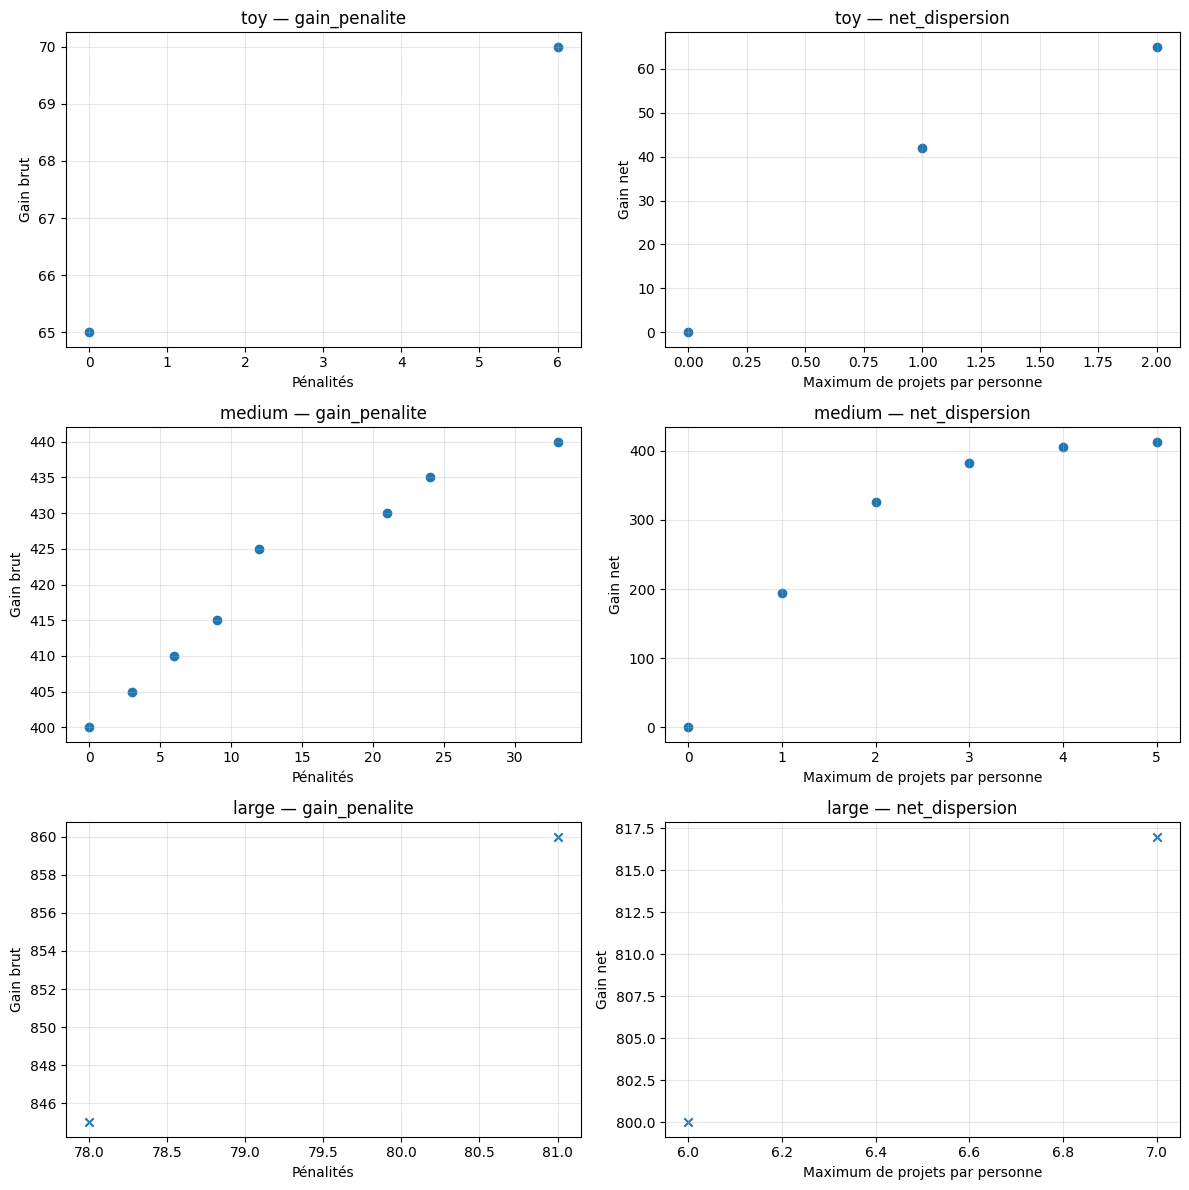

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for i, nom in enumerate(["toy", "medium", "large"]):
    for j, variante in enumerate(variantes):
        r = next(r for r in resultats if r["instance"] == nom and r["variante"] == variante)
        ax = axes[i, j]
        points = r["points"] if r["complet"] else r["candidats_non_certifies"]
        if points:
            couts = [p["cout"] for p in points]
            gains = [p["benefice"] for p in points]
            ax.scatter(couts, gains, marker="o" if r["complet"] else "x")
        else:
            ax.text(.5, .5, r["arret"], transform=ax.transAxes, ha="center", wrap=True)
        ax.set_title(nom + " — " + variante)
        ax.set_xlabel("Pénalités" if j == 0 else "Maximum de projets par personne")
        ax.set_ylabel("Gain brut" if j == 0 else "Gain net")
        ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(sortie / "fronts.png", dpi=160)
plt.show()

## Le planning : qui fait quoi ?

On prend le point toy sans pénalité et on affiche les affectations jour par jour. Il peut y avoir plusieurs plannings pour un même couple de critères. Ici, on en montre un, puis on recalcule ses besoins couverts et ses dates à partir des affectations.


In [7]:
r_toy = next(r for r in resultats if r["instance"] == "toy" and r["variante"] == "gain_penalite")
point = min(r_toy["points"], key=lambda p: p["cout"])
d = instances["toy"]
noms = [p["name"] for p in d["staff"]]
jours = list(range(1, d["horizon"] + 1))
planning = pd.DataFrame("Libre", index=noms, columns=jours)
for personne in d["staff"]:
    for t in personne["vacations"]:
        planning.loc[personne["name"], t] = "Congé"
for a in point["affectations"]:
    planning.loc[a["personne"], a["jour"]] = a["projet"] + " / " + a["competence"]
bilan = evaluer_planning(d, point["affectations"], point["retenus"])
print("Gain :", bilan["gain"], "Pénalités :", bilan["penalite"])
display(planning)
display(pd.DataFrame(bilan["projets"]))
planning.to_csv(sortie / "planning_toy.csv")

Gain : 65 Pénalités : 0


,1,2,3,4,5
Olivia,Job1 / B,Job4 / B,Job1 / A,Job3 / C,Job5 / C
Liam,Congé,Libre,Job4 / B,Job3 / A,Libre
Emma,Job4 / C,Congé,Job1 / C,Job3 / C,Job5 / C


,projet,retenu,debut,fin,echeance,retard,duree,gain,penalite
0,Job1,True,1,3,3,0,3,20,0
1,Job2,False,0,0,3,0,0,0,0
2,Job3,True,4,4,4,0,1,15,0
3,Job4,True,1,3,3,0,3,20,0
4,Job5,True,5,5,5,0,1,10,0


## Bilan

Les fronts complets permettent de comparer les compromis sur toy, medium et les instances générées. Les quatre candidats de large donnent déjà des plannings réalisables, mais il faudrait poursuivre les calculs pour connaître le front complet.


In [8]:
termines = sum(r["complet"] for r in resultats)
points = sum(len(r["points"]) for r in resultats)
candidats = sum(len(r["candidats_non_certifies"]) for r in resultats)
print("Études complètes :", termines, "/", len(resultats))
print("Points non dominés :", points)
print("Candidats des études interrompues :", candidats)

Études complètes : 28 / 30
Points non dominés : 89
Candidats des études interrompues : 4
